# 10. Benchmark aktywnych algorytmów Original w aplikacji

Notebook porównuje pięć aktywnych artefaktów `current/optimized` bez łączenia ich z URL Corpus. Mierzy ekstrakcję URL, live feature extraction, klasyfikator i API end-to-end.

Jedyny adres używany w badaniu to `https://example.com/account/verify?token=benchmark`. Cold-start jest osobny. Warm API: 1 rozgrzewka i 30 żądań. Komponenty: 10 rozgrzewek i 100 pomiarów. Własne kontenery są kończone w `finally`.


In [1]:
import importlib
import os
import sys
from pathlib import Path


def locate_backend_root():
    candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    for candidate in candidates:
        nested_backend = candidate / 'backend'
        if (candidate / 'config').is_dir() and (candidate / 'notebooks').is_dir():
            return candidate
        if (nested_backend / 'config').is_dir() and (nested_backend / 'notebooks').is_dir():
            return nested_backend
    raise FileNotFoundError('Nie znaleziono katalogu backend')


backend_root = locate_backend_root()
notebooks_dir = backend_root / 'notebooks' / 'original'
os.chdir(notebooks_dir)
sys.path.insert(0, str(backend_root))
os.environ.setdefault('MPLCONFIGDIR', '/tmp/phishing-detector-matplotlib')
if 'utils.notebook_plot_style' in sys.modules:
    importlib.reload(sys.modules['utils.notebook_plot_style'])
print(f'Backend: {backend_root}')


Backend: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/backend


In [2]:
import json
from time import perf_counter_ns

import numpy as np
import pandas as pd

os.environ['HOST_BACKEND_PATH'] = str(backend_root.resolve())

from app import app as flask_app
import app.routes as app_routes
from app.dependencies import phishing_service
from config.project_paths import RESULTS_ROOT
from extractors.content.url_extractor import URLExtractor
from services.container_config import ContainerConfig
from services.ml_prediction_service import MLPredictionService
from services.url_feature_service import URLFeatureService
from utils.benchmark_plots import plot_realtime_results
from utils.research_benchmark import (
    binary_metrics,
    classifier_probabilities,
    measure_ns,
    recommend_realtime,
    timing_summary_ns,
    validate_safe_url,
)

SAFE_URL = 'https://example.com/account/verify?token=benchmark'
SAFE_MESSAGE = f'Wiadomość testowa: {SAFE_URL}'
WARMUPS = 10
REPETITIONS = 100
API_WARMUPS = 1
API_REPETITIONS = 30
CLASSIFIER_P95_LIMIT_MS = 100.0
API_P95_LIMIT_MS = 2000.0
ALGORITHMS = ('logistic_regression', 'random_forest', 'xgboost', 'svm', 'mlp')
MODEL_LABELS = {
    'logistic_regression': 'Regresja Logistyczna',
    'random_forest': 'Random Forest',
    'xgboost': 'XGBoost',
    'svm': 'SVM',
    'mlp': 'MLP',
}
SCENARIOS = [
    {'scenario': f'current_{algorithm}', 'dataset': 'current', 'algorithm': algorithm}
    for algorithm in ALGORITHMS
]
OUTPUT_DIR = RESULTS_ROOT / 'original' / 'realtime_application'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
validate_safe_url(SAFE_URL)
assert app_routes.__name__ == 'app.routes'
print(f"NETWORK_MODE={ContainerConfig.NETWORK_MODE!r}")
print(f'Wyniki: {OUTPUT_DIR}')


2026-07-29 18:30:20 | INFO | App | ============================================================


2026-07-29 18:30:20 | INFO | App | 🚀 PHISHING DETECTOR BACKEND STARTING


2026-07-29 18:30:20 | INFO | App | ============================================================


2026-07-29 18:30:20 | INFO | App | ✅ Flask app initialized with CORS


2026-07-29 18:30:21 | DEBUG | matplotlib | matplotlib data path: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/.venv/lib/python3.13/site-packages/matplotlib/mpl-data


...

2026-07-29 18:30:22 | INFO | ContainerOrchestrator | DockerSandboxClient initialized | Docker client: Connected


2026-07-29 18:30:22 | INFO | ContainerOrchestrator | Host backend path: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/backend


2026-07-29 18:30:22 | DEBUG | urllib3.connectionpool | http://localhost:None "GET /v1.55/containers/json?limit=-1&all=1&size=0&trunc_cmd=0&filters=%7B%22name%22%3A+%5B%22phishing-sandbox-%22%5D%7D HTTP/1.1" 200 None


2026-07-29 18:30:22 | INFO | PhishingDetectionService | ✅ PhishingDetectionService initialized


NETWORK_MODE='bridge'
Wyniki: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/realtime_application


## Pomiary komponentowe

Ekstrakcja URL mierzy parser treści. Live feature extraction obejmuje rzeczywiste operacje sieciowe dla `example.com`. Pomiar klasyfikatora korzysta z aktywnego payloadu, właściwego skalera i gotowego wektora, bez kosztu ekstrakcji oraz API.

In [3]:
url_extractor = URLExtractor()
feature_service = URLFeatureService(timeout=5, apply_network_defaults=False)
prediction_service = MLPredictionService()
extracted_urls = url_extractor.extract_from_text(SAFE_MESSAGE)
assert extracted_urls == {SAFE_URL}
url_samples = measure_ns(
    lambda: url_extractor.extract_from_text(SAFE_MESSAGE), WARMUPS, REPETITIONS
)
feature_samples = measure_ns(
    lambda: feature_service.extract(SAFE_URL, 'optimized'), WARMUPS, REPETITIONS
)
live_features = feature_service.extract(SAFE_URL, 'optimized')
component_raw_rows = [
    *[{'component': 'url_extraction', 'scenario': 'shared', 'repetition': index, 'duration_ns': value}
      for index, value in enumerate(url_samples, 1)],
    *[{'component': 'live_feature_extraction', 'scenario': 'shared', 'repetition': index, 'duration_ns': value}
      for index, value in enumerate(feature_samples, 1)],
]
component_summary_rows = [
    {'component': 'url_extraction', 'scenario': 'shared', 'warmups': WARMUPS,
     'repetitions': REPETITIONS, **timing_summary_ns(url_samples)},
    {'component': 'live_feature_extraction', 'scenario': 'shared', 'warmups': WARMUPS,
     'repetitions': REPETITIONS, **timing_summary_ns(feature_samples)},
]
active_rows = []
for scenario in SCENARIOS:
    algorithm = scenario['algorithm']
    dataset = scenario['dataset']
    payload = prediction_service.load_model(algorithm, 'optimized', dataset)
    vector = prediction_service._build_vector(live_features, payload, algorithm)
    operation = lambda item=payload, name=algorithm, values=vector: prediction_service._predict_payload(
        item, name, values
    )
    samples = measure_ns(operation, WARMUPS, REPETITIONS)
    component_raw_rows.extend({
        'component': 'classifier',
        'scenario': scenario['scenario'],
        'repetition': index,
        'duration_ns': value,
    } for index, value in enumerate(samples, 1))
    component_summary_rows.append({
        'component': 'classifier',
        'scenario': scenario['scenario'],
        'warmups': WARMUPS,
        'repetitions': REPETITIONS,
        **timing_summary_ns(samples),
    })
    artifact_path = prediction_service.repository._model_path(algorithm, 'optimized', dataset)
    test_path = backend_root / 'data' / 'test' / 'test_dataset_optimized.csv'
    test_frame = pd.read_csv(test_path)
    test_values = test_frame[list(payload['feature_names'])]
    scaler = payload.get('scaler')
    test_values = scaler.transform(test_values) if scaler is not None else test_values
    probabilities = classifier_probabilities(payload['model'], test_values)
    metrics = binary_metrics(
        test_frame['phishing'].to_numpy(dtype=int),
        probabilities,
        float(payload.get('decision_threshold', 0.5)),
    )
    active_rows.append({
        **scenario,
        'features': len(payload['feature_names']),
        'artifact_bytes': artifact_path.stat().st_size,
        'test_rows': len(test_frame),
        'f1': metrics['f1'],
        'false_positive_rate': metrics['false_positive_rate'],
    })
component_raw = pd.DataFrame(component_raw_rows)
component_summary = pd.DataFrame(component_summary_rows)
active_metrics = pd.DataFrame(active_rows)
component_raw.to_csv(OUTPUT_DIR / 'component_timing_raw.csv', index=False)
component_summary.to_csv(OUTPUT_DIR / 'component_timing_summary.csv', index=False)
active_metrics.to_csv(OUTPUT_DIR / 'active_artifact_metrics.csv', index=False)
display(component_summary)
display(active_metrics)


2026-07-29 18:30:22 | INFO | URLFeatureService |    🔍 Extracting features for: https://example.com/account/verify?token=benchmark


2026-07-29 18:30:22 | DEBUG | filelock | Attempting to acquire lock 4897655504 on /tmp/tldextract/publicsuffix.org-tlds/906337bdfc421126a1477ade77793840.tldextract.json.lock


2026-07-29 18:30:22 | DEBUG | filelock | Lock 4897655504 acquired on /tmp/tldextract/publicsuffix.org-tlds/906337bdfc421126a1477ade77793840.tldextract.json.lock


2026-07-29 18:30:22 | DEBUG | filelock | Attempting to release lock 4897655504 on /tmp/tldextract/publicsuffix.org-tlds/906337bdfc421126a1477ade77793840.tldextract.json.lock


2026-07-29 18:30:22 | DEBUG | filelock | Lock 4897655504 released on /tmp/tldextract/publicsuffix.org-tlds/906337bdfc421126a1477ade77793840.tldextract.json.lock


...

2026-07-29 18:30:43 | DEBUG | h5py._conv | Creating converter from 5 to 7


2026-07-29 18:30:43 | DEBUG | h5py._conv | Creating converter from 7 to 5


2026-07-29 18:30:43 | DEBUG | h5py._conv | Creating converter from 5 to 7


,component,scenario,warmups,repetitions,mean_ms,median_ms,std_ms,p95_ms,ms_per_url,urls_per_second
0,url_extraction,shared,10,100,0.014477,0.014500,0.000542,0.014835,0.014477,69072.746726
1,live_feature_extraction,shared,10,100,26.401022,26.385666,1.761792,29.296476,26.401022,37.877321
2,classifier,current_logistic_regression,10,100,0.025997,0.025917,0.001830,0.028500,0.025997,38465.917658
3,classifier,current_random_forest,10,100,13.794419,13.794376,1.720969,14.515196,13.794419,72.493085
4,classifier,current_xgboost,10,100,2.175030,2.140938,0.196259,2.487481,2.175030,459.763786
5,classifier,current_svm,10,100,0.337584,0.325250,0.028897,0.386152,0.337584,2962.228681
6,classifier,current_mlp,10,100,1.432726,1.365500,0.201928,1.616000,1.432726,697.970275


,scenario,dataset,algorithm,features,artifact_bytes,test_rows,f1,false_positive_rate
0,current_logistic_regression,current,logistic_regression,74,1309,40000,0.944344,0.05555
1,current_random_forest,current,random_forest,74,125777124,40000,0.979509,0.01220
2,current_xgboost,current,xgboost,74,1607114,40000,0.972166,0.03765
3,current_svm,current,svm,74,3933113,40000,0.960282,0.03270
4,current_mlp,current,mlp,74,249155,40000,0.964186,0.02530


## API end-to-end

Pomiar przechodzi przez `/api/analyze-sms`, ekstrakcję URL, sandbox Docker, live feature extraction, aktywny algorytm i serializację odpowiedzi. Kontener działa z faktycznym `NETWORK_MODE='bridge'`; wynik nie jest opisywany jako test bez sieci.


In [4]:
def api_request(client, scenario):
    return client.post(
        '/api/analyze-sms',
        data={
            'content': SAFE_MESSAGE,
            'models': scenario['algorithm'],
            'mode': 'optimized',
            'dataset': scenario['dataset'],
        },
        content_type='multipart/form-data',
    )


def technical_success(response):
    body = response.get_json(silent=True) or {}
    analysis = body.get('analysis') or []
    return response.status_code == 200 and bool(body.get('success')) and all(
        item.get('success') for item in analysis
    )


api_raw_rows = []
cold_start_rows = []
api_summary_rows = []
client = flask_app.test_client()
try:
    cold_started = perf_counter_ns()
    cold_response = api_request(client, SCENARIOS[0])
    cold_duration = perf_counter_ns() - cold_started
    cold_start_rows.append({
        **SCENARIOS[0],
        'duration_ns': cold_duration,
        'duration_ms': cold_duration / 1_000_000,
        'status_code': cold_response.status_code,
        'technical_success': technical_success(cold_response),
    })
    for scenario in SCENARIOS:
        for _ in range(API_WARMUPS):
            api_request(client, scenario)
        scenario_rows = []
        for repetition in range(1, API_REPETITIONS + 1):
            started = perf_counter_ns()
            response = api_request(client, scenario)
            duration = perf_counter_ns() - started
            row = {
                **scenario,
                'repetition': repetition,
                'duration_ns': duration,
                'status_code': response.status_code,
                'technical_success': technical_success(response),
            }
            api_raw_rows.append(row)
            scenario_rows.append(row)
        samples = [row['duration_ns'] for row in scenario_rows]
        api_summary_rows.append({
            **scenario,
            'warmups': API_WARMUPS,
            'repetitions': API_REPETITIONS,
            'success_rate': np.mean([row['technical_success'] for row in scenario_rows]),
            **timing_summary_ns(samples),
        })
finally:
    phishing_service.orchestrator.cleanup_all()

api_raw = pd.DataFrame(api_raw_rows)
cold_start = pd.DataFrame(cold_start_rows)
api_summary = pd.DataFrame(api_summary_rows)
api_raw.to_csv(OUTPUT_DIR / 'api_timing_raw.csv', index=False)
cold_start.to_csv(OUTPUT_DIR / 'cold_start.csv', index=False)
api_summary.to_csv(OUTPUT_DIR / 'api_timing_summary.csv', index=False)
display(cold_start)
display(api_summary)


2026-07-29 18:30:44 | INFO | PhishingDetectionService | ============================================================


2026-07-29 18:30:44 | INFO | PhishingDetectionService | 🚀 STARTING: SMS ANALYSIS


2026-07-29 18:30:44 | INFO | PhishingDetectionService |    Operation ID: 5001e010


2026-07-29 18:30:44 | INFO | PhishingDetectionService |    Parameters: content_length=69 | models=['logistic_regression'] | mode=optimized | dataset=current


2026-07-29 18:30:44 | INFO | PhishingDetectionService | ============================================================


...

2026-07-29 18:36:04 | DEBUG | urllib3.connectionpool | http://localhost:None "DELETE /v1.55/containers/3c45c2407ab92fd26fe3d7c2bf8fe46434788eb7604b0bdb46699aeefdfb1d2b?v=True&link=False&force=True HTTP/1.1" 204 0


2026-07-29 18:36:04 | DEBUG | ContainerOrchestrator |       - Container and volumes removed


2026-07-29 18:36:04 | INFO | ContainerOrchestrator | ✅ All containers cleaned up


,scenario,dataset,algorithm,duration_ns,duration_ms,status_code,technical_success
0,current_logistic_regression,current,logistic_regression,9371885959,9371.885959,200,True


,scenario,dataset,algorithm,warmups,repetitions,success_rate,mean_ms,median_ms,std_ms,p95_ms,ms_per_url,urls_per_second
0,current_logistic_regression,current,logistic_regression,1,30,1.0,1590.415585,1585.856146,104.608843,1791.368944,1590.415585,0.628766
1,current_random_forest,current,random_forest,1,30,1.0,1849.835863,1844.044750,86.945340,1966.744937,1849.835863,0.540589
2,current_xgboost,current,xgboost,1,30,1.0,1553.337743,1566.390000,108.235594,1641.848744,1553.337743,0.643775
3,current_svm,current,svm,1,30,1.0,1568.244453,1529.818958,110.964423,1793.439954,1568.244453,0.637656
4,current_mlp,current,mlp,1,30,1.0,2975.086856,2933.578417,200.752917,3239.403912,2975.086856,0.336125


In [5]:
classifier_summary = component_summary[
    component_summary['component'] == 'classifier'
][['scenario', 'p95_ms']].rename(columns={'p95_ms': 'classifier_p95_ms'})
assessment = (
    active_metrics
    .merge(classifier_summary, on='scenario')
    .merge(api_summary[['scenario', 'p95_ms', 'success_rate']], on='scenario')
    .rename(columns={'p95_ms': 'api_p95_ms'})
)
assessment['classifier_gate_passed'] = assessment['classifier_p95_ms'] <= CLASSIFIER_P95_LIMIT_MS
assessment['api_gate_passed'] = assessment['api_p95_ms'] <= API_P95_LIMIT_MS
assessment['success_gate_passed'] = assessment['success_rate'] == 1.0
assessment['eligible'] = assessment[
    ['classifier_gate_passed', 'api_gate_passed', 'success_gate_passed']
].all(axis=1)
recommendation = recommend_realtime(assessment.to_dict(orient='records'))
recommendation_frame = pd.DataFrame(
    [recommendation] if recommendation is not None else [{'status': 'Brak algorytmu spełniającego progi'}]
)
assessment.to_csv(OUTPUT_DIR / 'realtime_quality_assessment.csv', index=False)
recommendation_frame.to_csv(OUTPUT_DIR / 'conditional_recommendation.csv', index=False)
quality_report = {
    'network_mode': ContainerConfig.NETWORK_MODE,
    'safe_url': SAFE_URL,
    'criteria': {
        'classifier_p95_max_ms': CLASSIFIER_P95_LIMIT_MS,
        'api_p95_max_ms': API_P95_LIMIT_MS,
        'technical_success_rate': 1.0,
    },
    'recommendation_pool': 'backend/models current/optimized',
    'results': assessment.to_dict(orient='records'),
    'recommendation': recommendation,
}
(OUTPUT_DIR / 'quality_gate.json').write_text(
    json.dumps(quality_report, ensure_ascii=False, indent=2) + '\n',
    encoding='utf-8',
)
display(assessment)
recommendation_frame


,scenario,dataset,algorithm,features,artifact_bytes,test_rows,f1,false_positive_rate,classifier_p95_ms,api_p95_ms,success_rate,classifier_gate_passed,api_gate_passed,success_gate_passed,eligible
0,current_logistic_regression,current,logistic_regression,74,1309,40000,0.944344,0.05555,0.028500,1791.368944,1.0,True,True,True,True
1,current_random_forest,current,random_forest,74,125777124,40000,0.979509,0.01220,14.515196,1966.744937,1.0,True,True,True,True
2,current_xgboost,current,xgboost,74,1607114,40000,0.972166,0.03765,2.487481,1641.848744,1.0,True,True,True,True
3,current_svm,current,svm,74,3933113,40000,0.960282,0.03270,0.386152,1793.439954,1.0,True,True,True,True
4,current_mlp,current,mlp,74,249155,40000,0.964186,0.02530,1.616000,3239.403912,1.0,True,False,True,False


,scenario,dataset,algorithm,features,artifact_bytes,test_rows,f1,false_positive_rate,classifier_p95_ms,api_p95_ms,success_rate,classifier_gate_passed,api_gate_passed,success_gate_passed,eligible
0,current_random_forest,current,random_forest,74,125777124,40000,0.979509,0.0122,14.515196,1966.744937,1.0,True,True,True,True


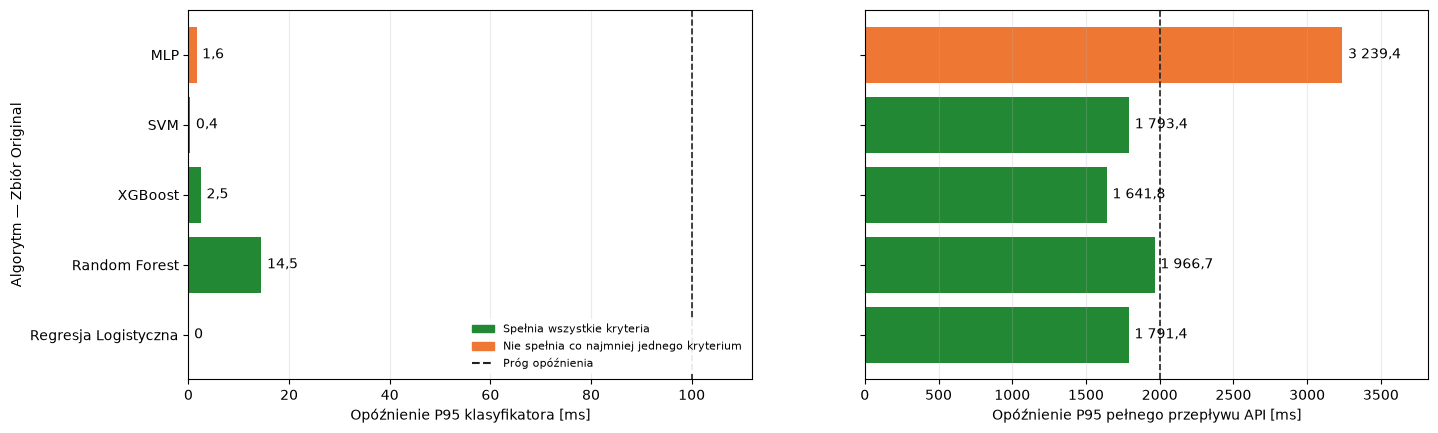

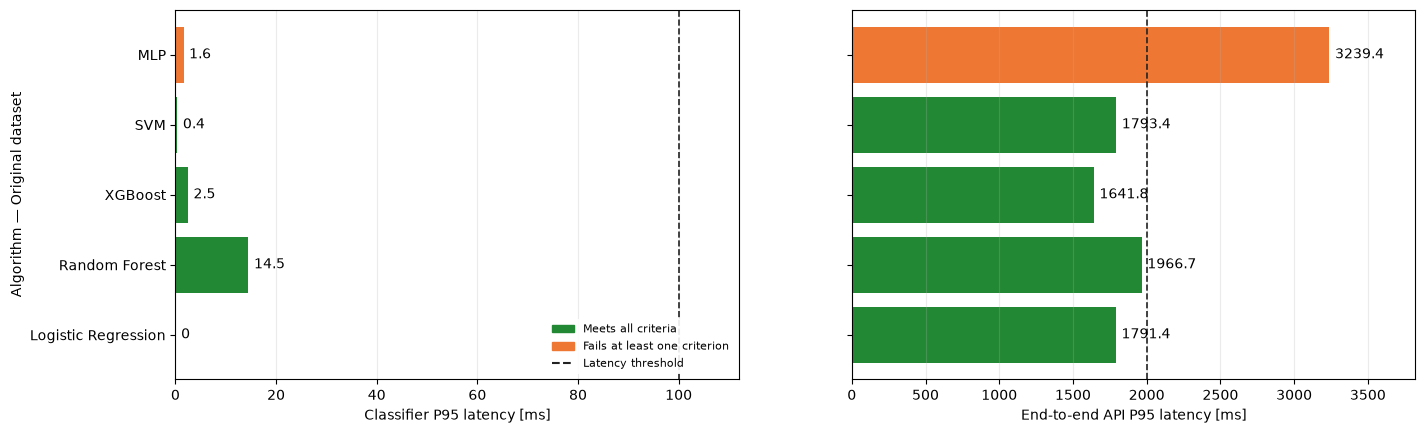

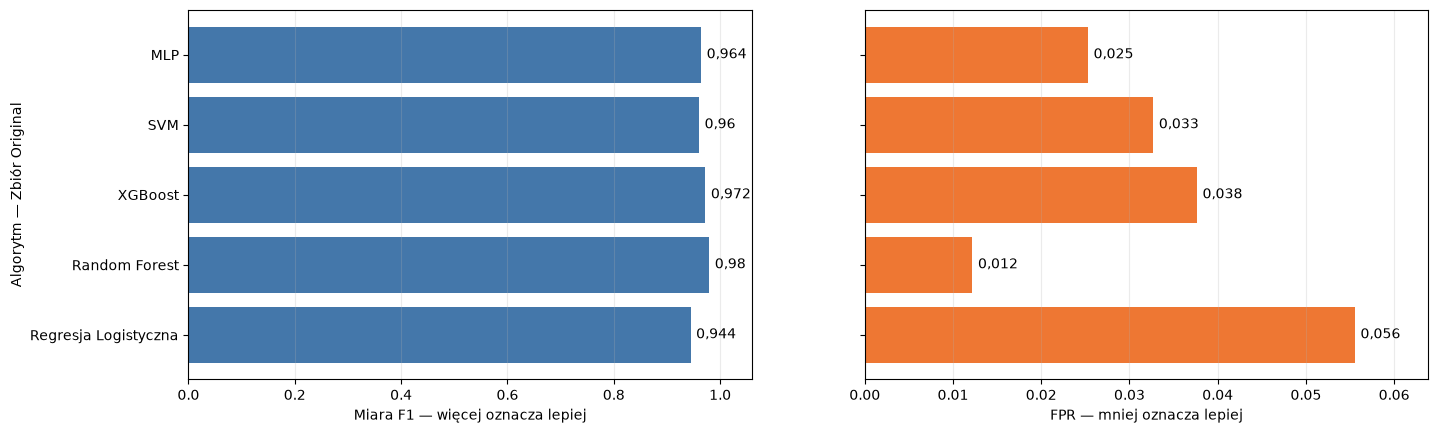

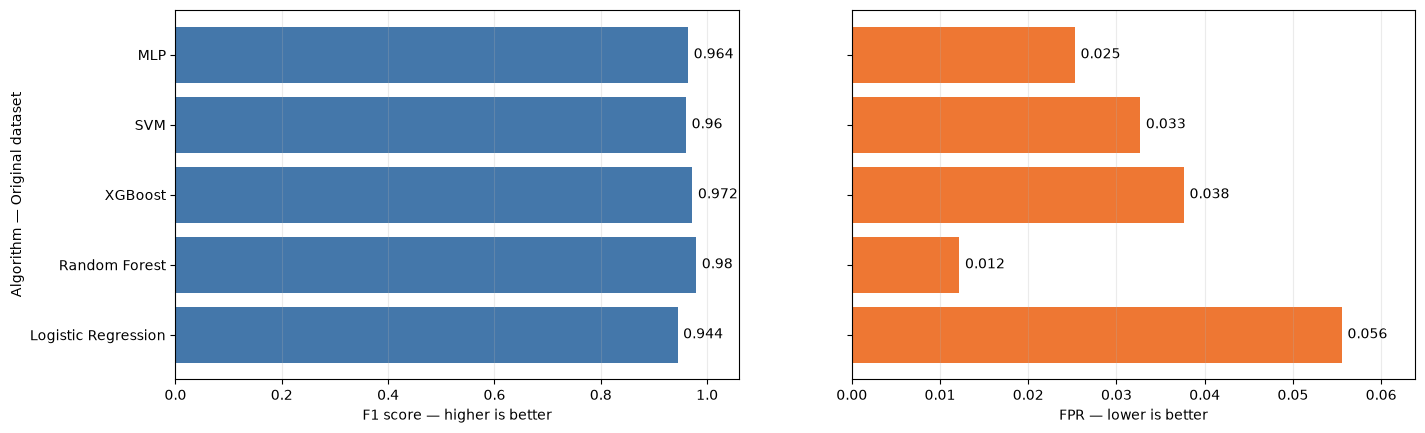

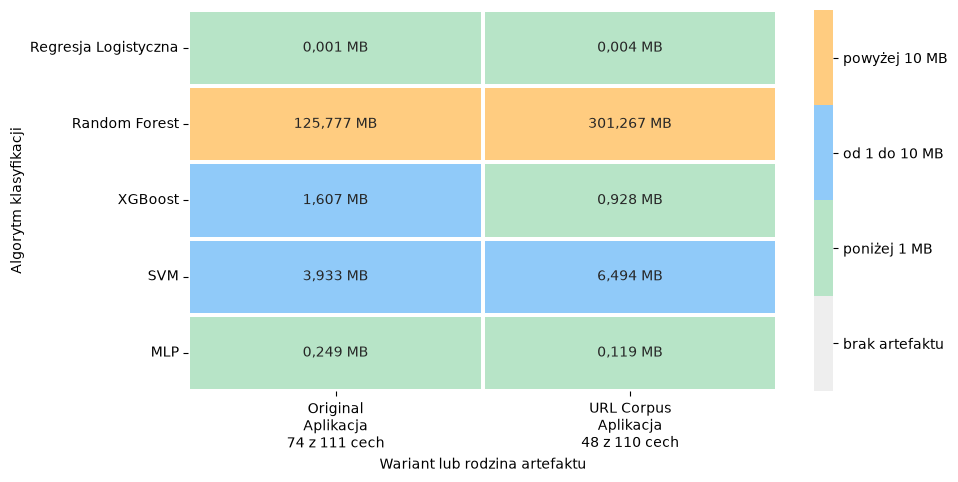

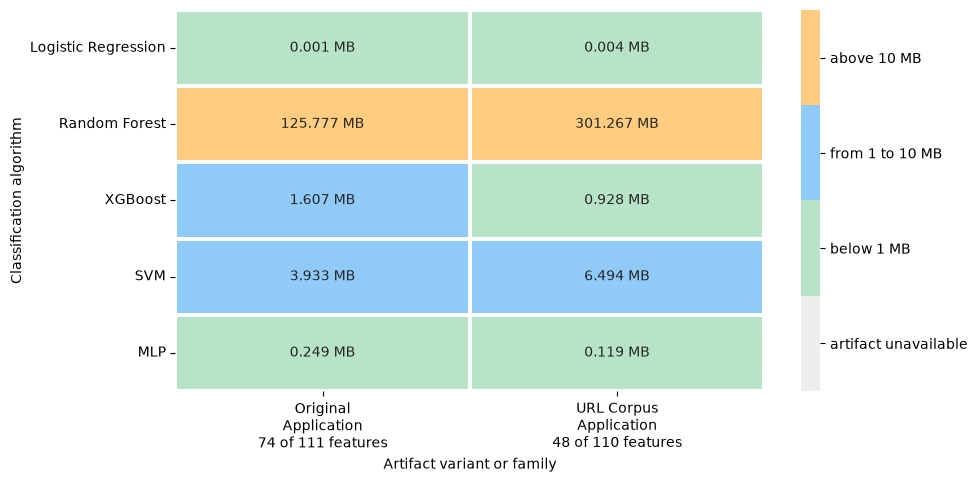

In [1]:
environment = {
    'network_mode': ContainerConfig.NETWORK_MODE,
    'host_backend_path': os.environ['HOST_BACKEND_PATH'],
    'safe_url': SAFE_URL,
    'component_warmups': WARMUPS,
    'component_repetitions': REPETITIONS,
    'api_warmups': API_WARMUPS,
    'api_repetitions': API_REPETITIONS,
    'cold_start_excluded_from_warm_summary': True,
    'artifact_source': str((backend_root / 'models').resolve()),
}
(OUTPUT_DIR / 'environment.json').write_text(
    json.dumps(environment, ensure_ascii=False, indent=2) + '\n',
    encoding='utf-8',
)
artifact_groups = {
    family: pd.read_csv(
        RESULTS_ROOT / family / 'realtime_application' / 'realtime_quality_assessment.csv'
    )
    for family in ('original', 'url_corpus')
}
plot_realtime_results(
    assessment, OUTPUT_DIR, MODEL_LABELS, CLASSIFIER_P95_LIMIT_MS,
    API_P95_LIMIT_MS, artifact_groups,
)


## Interpretacja

- klasyfikator i API mają osobne panele oraz skale, więc koszt API nie ukrywa różnic algorytmów;
- pionowe linie pokazują progi P95, a kolor odróżnia warianty spełniające cały gate;
- F1 i FPR są pokazane osobno, z jawnym kierunkiem „więcej” i „mniej”;
- cold-start nie jest mieszany z pomiarami warm;
- 100% sukcesu oznacza technicznie poprawne odpowiedzi, nie poprawność etykiety;
- rekomendacja dotyczy wyłącznie rodziny Original i nie zmienia konfiguracji aplikacji.


In [7]:
if recommendation is None:
    print('Brak rekomendacji: żaden algorytm Original nie spełnił wszystkich progów.')
else:
    print(
        f"Warunkowa rekomendacja: {MODEL_LABELS[recommendation['algorithm']]}; "
        f"F1={recommendation['f1']:.4f}, FPR={recommendation['false_positive_rate']:.4f}, "
        f"API P95={recommendation['api_p95_ms']:.2f} ms."
    )
print(f"Faktyczny tryb sieci kontenera: {ContainerConfig.NETWORK_MODE!r}.")
print('Domyślna konfiguracja aplikacji pozostała bez zmian.')


Warunkowa rekomendacja: Random Forest; F1=0.9795, FPR=0.0122, API P95=1966.74 ms.
Faktyczny tryb sieci kontenera: 'bridge'.
Domyślna konfiguracja aplikacji pozostała bez zmian.
